# Inspect quiescent sample photometry

Plot one observed-frame JWST photometry figure per target using the local photometry FITS tables.


In [11]:
import numpy as np

import smplotlib
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.lines import Line2D

import astropy.units as u
from astropy.table import Table
from sedpy.observate import load_filters


In [12]:
LAPIS_DIR = Path('/Users/Jonah/PhD/Research/lapis')
PHOT_DIR = LAPIS_DIR / 'data_processed' / 'photometry'
FIG_DIR = LAPIS_DIR / 'figures' / 'inspect_quiescent_sample' / 'photometry'
FIG_DIR.mkdir(parents=True, exist_ok=True)

photometry_files = {
    '1397': '1397_jades_dr5_photometry.fits',
    '72127': '72127_jades_dr5_photometry.fits',
    '80660': '80660_jades_dr5_photometry.fits',
    '8290': '8290_jades_dr5_photometry.fits',
    '8777': '8777_jades_dr5_photometry.fits',
    'gs-9209': 'gs-9209_jades_dr5_photometry.fits',
    'cos-z5-q1': 'cos-z5-q1_dja_v7_photometry.fits',
    'gs-z5-q1': 'gs-z5-q1_dja_v7_photometry.fits',
}

galaxy_redshifts = {
    '1397': 4.22,
    '72127': 4.13,
    '80660': 4.39,
    '8290': 4.37,
    '8777': 4.66,
    'gs-9209': 4.658,
    'cos-z5-q1': 5.11,
    'gs-z5-q1': 5.39,
}

JWST_FILTERS = [
    'F070W', 'F090W', 'F115W', 'F150W', 'F162M', 'F182M', 'F200W',
    'F210M', 'F250M', 'F277W', 'F300M', 'F335M', 'F356W', 'F410M',
    'F430M', 'F444W', 'F460M', 'F480M', 'F560W', 'F770W', 'F1000W',
    'F1280W', 'F1500W', 'F1800W', 'F2100W', 'F2550W'
]
MIRI_FILTERS = ['F560W', 'F770W', 'F1000W', 'F1280W', 'F1500W', 'F1800W', 'F2100W', 'F2550W']
NIRCAM_FILTERS = [filt for filt in JWST_FILTERS if filt not in MIRI_FILTERS]

sedpy_filters = load_filters([f'jwst_{filter_name.lower()}' for filter_name in JWST_FILTERS])
sedpy_filter_map = {filter_name: sedpy_filter for filter_name, sedpy_filter in zip(JWST_FILTERS, sedpy_filters)}

flambda_unit = u.erg / (u.s * u.cm**2 * u.AA)
cgs_plot_scale = 1e20
linear_rest_ticks = np.arange(0.1, 1.11, 0.1)
log_rest_ticks = np.array([0.1, 0.3, 0.6, 1.0, 2.0, 5.0])

nircam_plot_kwargs = {
    'marker': 'o',
    'ms': 7,
    'mfc': 'white',
    'mec': 'black',
    'ecolor': 'black',
    'elinewidth': 1.1,
    'capsize': 0,
    'ls': 'none',
    'zorder': 4,
}
miri_plot_kwargs = {
    'marker': 's',
    'ms': 7,
    'mfc': 'white',
    'mec': 'black',
    'ecolor': 'black',
    'elinewidth': 1.1,
    'capsize': 0,
    'ls': 'none',
    'zorder': 5,
}

legend_handle_map = {
    'NIRCam photometry': Line2D([0], [0], marker='o', ms=7, mfc='white', mec='black', color='black', ls='none', label='NIRCam photometry'),
    'MIRI photometry': Line2D([0], [0], marker='s', ms=7, mfc='white', mec='black', color='black', ls='none', label='MIRI photometry'),
    '1$\\sigma$ upper limit': Line2D([0], [0], color='red', lw=1.5, label='1$\\sigma$ upper limit'),
}


In [15]:
def obs_to_rest_factory(zred):
    """Return one observed-to-rest wavelength converter."""

    return lambda wave_obs_um: wave_obs_um / (1 + zred)


def rest_to_obs_factory(zred):
    """Return one rest-to-observed wavelength converter."""

    return lambda wave_rest_um: wave_rest_um * (1 + zred)


def convert_photometry_to_cgs(flux_njy, err_njy, wave_eff_um):
    """Convert fluxes and errors from nJy to the plotting CGS scale."""

    wave_quantity = np.asarray(wave_eff_um, dtype=float) * u.um
    flux_cgs = (np.asarray(flux_njy, dtype=float) * u.nJy).to(flambda_unit, equivalencies=u.spectral_density(wave_quantity)).value
    err_cgs = (np.asarray(err_njy, dtype=float) * u.nJy).to(flambda_unit, equivalencies=u.spectral_density(wave_quantity)).value
    return cgs_plot_scale * flux_cgs, cgs_plot_scale * err_cgs


def get_filter_waves(filters):
    """Return effective wavelengths and band edges from sedpy."""

    wave_eff = np.full(len(filters), np.nan, dtype=float)
    wave_min = np.full(len(filters), np.nan, dtype=float)
    wave_max = np.full(len(filters), np.nan, dtype=float)

    for i, filter_name in enumerate(filters):
        sedpy_filter = sedpy_filter_map.get(filter_name)
        if sedpy_filter is None:
            continue

        wave_eff[i] = sedpy_filter.wave_effective / 1e4
        ok = np.asarray(sedpy_filter.transmission) > 0
        if np.any(ok):
            wave_min[i] = np.nanmin(sedpy_filter.wavelength[ok]) / 1e4
            wave_max[i] = np.nanmax(sedpy_filter.wavelength[ok]) / 1e4

    return wave_eff, wave_min, wave_max


def load_target_photometry(phot_file):
    """Load one JWST-only photometry table."""

    table = Table.read(phot_file)
    filters = np.asarray(table['FILTER'], dtype=str)
    flux_njy = np.asarray(table['DATA'], dtype=float)
    err_njy = np.asarray(table['ERR'], dtype=float)
    wave_pivot_um = np.asarray(table['WAVE_PIVOT'], dtype=float)
    valid = np.asarray(table['VALID'], dtype=bool) if 'VALID' in table.colnames else np.ones(len(table), dtype=bool)

    jwst = np.isin(filters, JWST_FILTERS)
    ok = jwst & valid & np.isfinite(flux_njy) & np.isfinite(err_njy) & np.isfinite(wave_pivot_um)

    filters = filters[ok]
    flux_njy = flux_njy[ok]
    err_njy = err_njy[ok]

    wave_eff_um, wave_min_um, wave_max_um = get_filter_waves(filters)
    missing_wave = ~np.isfinite(wave_eff_um)
    wave_eff_um[missing_wave] = wave_pivot_um[ok][missing_wave]

    return {
        'filters': filters,
        'flux_njy': flux_njy,
        'err_njy': err_njy,
        'wave_eff_um': wave_eff_um,
        'wave_min_um': wave_min_um,
        'wave_max_um': wave_max_um,
    }
def plot_target_photometry(target_id, phot_file, zred):
    """Plot one JWST photometry figure for a target."""

    phot_data = load_target_photometry(phot_file)
    filters = phot_data['filters']
    flux_cgs, err_cgs = convert_photometry_to_cgs(phot_data['flux_njy'], phot_data['err_njy'], phot_data['wave_eff_um'])

    nircam = np.isin(filters, NIRCAM_FILTERS)
    miri = np.isin(filters, MIRI_FILTERS)

    fig, ax = plt.subplots(figsize=(7.2, 4.8))

    nircam_xerr = np.vstack([
        phot_data['wave_eff_um'][nircam] - phot_data['wave_min_um'][nircam],
        phot_data['wave_max_um'][nircam] - phot_data['wave_eff_um'][nircam],
    ])
    nircam_xerr[:, ~np.all(np.isfinite(nircam_xerr), axis=0)] = np.nan
    nircam_detected = nircam & (flux_cgs >= 0)
    if np.any(nircam_detected):
        ax.errorbar(
            phot_data['wave_eff_um'][nircam_detected], flux_cgs[nircam_detected], yerr=err_cgs[nircam_detected],
            xerr=nircam_xerr[:, flux_cgs[nircam] >= 0], **nircam_plot_kwargs,
        )
    nircam_upper = nircam & (flux_cgs < 0)
    if np.any(nircam_upper):
        ax.errorbar(
            phot_data['wave_eff_um'][nircam_upper], err_cgs[nircam_upper], yerr=err_cgs[nircam_upper],
            xerr=nircam_xerr[:, flux_cgs[nircam] < 0], fmt='none', uplims=True,
            ecolor='red', elinewidth=1.1, capsize=0, zorder=4,
        )

    miri_xerr = np.vstack([
        phot_data['wave_eff_um'][miri] - phot_data['wave_min_um'][miri],
        phot_data['wave_max_um'][miri] - phot_data['wave_eff_um'][miri],
    ])
    miri_xerr[:, ~np.all(np.isfinite(miri_xerr), axis=0)] = np.nan
    miri_detected = miri & (flux_cgs >= 0)
    if np.any(miri_detected):
        ax.errorbar(
            phot_data['wave_eff_um'][miri_detected], flux_cgs[miri_detected], yerr=err_cgs[miri_detected],
            xerr=miri_xerr[:, flux_cgs[miri] >= 0], **miri_plot_kwargs,
        )
    miri_upper = miri & (flux_cgs < 0)
    if np.any(miri_upper):
        ax.errorbar(
            phot_data['wave_eff_um'][miri_upper], err_cgs[miri_upper], yerr=err_cgs[miri_upper],
            xerr=miri_xerr[:, flux_cgs[miri] < 0], fmt='none', uplims=True,
            ecolor='red', elinewidth=1.1, capsize=0, zorder=5,
        )

    ymax_candidates = np.concatenate([flux_cgs[flux_cgs >= 0] + err_cgs[flux_cgs >= 0], err_cgs[flux_cgs < 0]])
    ymax = 1.15 * np.nanmax(ymax_candidates) if ymax_candidates.size > 0 else 1.0

    ax.axhline(0.0, color='lightgrey', lw=1.0, zorder=0)
    if np.any(miri):
        ax.set_xscale('log')
    ax.set_xlim(0.85 * np.nanmin(phot_data['wave_min_um']), 1.15 * np.nanmax(phot_data['wave_max_um']))
    ax.set_ylim(-0.05 * ymax, ymax)
    ax.set_xlabel(r'$\lambda_{\rm obs}$ [$\mu$m]')
    ax.set_ylabel(r'$f_{\lambda}$ [$10^{-20}$ erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$]')
    ax.set_title(f'{target_id}  z={zred:.3f}')

    ax_top = ax.secondary_xaxis('top', functions=(obs_to_rest_factory(zred), rest_to_obs_factory(zred)))
    ax.tick_params(axis='x', which='both', top=False, labeltop=False)
    rest_ticks = log_rest_ticks if np.any(miri) else linear_rest_ticks
    ax_top.set_xticks(rest_ticks)
    ax_top.set_xticklabels([f'{tick:.1f}' for tick in rest_ticks])
    ax_top.set_xlabel(r'$\lambda_{\rm rest}$ [$\mu$m]')

    legend_handles = [legend_handle_map['NIRCam photometry'], legend_handle_map['MIRI photometry']]
    if np.any(flux_cgs < 0):
        legend_handles.append(legend_handle_map['1$\\sigma$ upper limit'])
    ax.legend(legend_handles, [handle.get_label() for handle in legend_handles], loc='best', frameon=True)

    save_path = FIG_DIR / f'{target_id}_photometry.png'
    fig.savefig(save_path, dpi=250, bbox_inches='tight')
    
    return save_path


[PosixPath('/Users/Jonah/PhD/Research/lapis/figures/inspect_quiescent_sample/photometry/1397_photometry.png'),
 PosixPath('/Users/Jonah/PhD/Research/lapis/figures/inspect_quiescent_sample/photometry/72127_photometry.png'),
 PosixPath('/Users/Jonah/PhD/Research/lapis/figures/inspect_quiescent_sample/photometry/80660_photometry.png'),
 PosixPath('/Users/Jonah/PhD/Research/lapis/figures/inspect_quiescent_sample/photometry/8290_photometry.png'),
 PosixPath('/Users/Jonah/PhD/Research/lapis/figures/inspect_quiescent_sample/photometry/8777_photometry.png'),
 PosixPath('/Users/Jonah/PhD/Research/lapis/figures/inspect_quiescent_sample/photometry/gs-9209_photometry.png'),
 PosixPath('/Users/Jonah/PhD/Research/lapis/figures/inspect_quiescent_sample/photometry/cos-z5-q1_photometry.png'),
 PosixPath('/Users/Jonah/PhD/Research/lapis/figures/inspect_quiescent_sample/photometry/gs-z5-q1_photometry.png')]

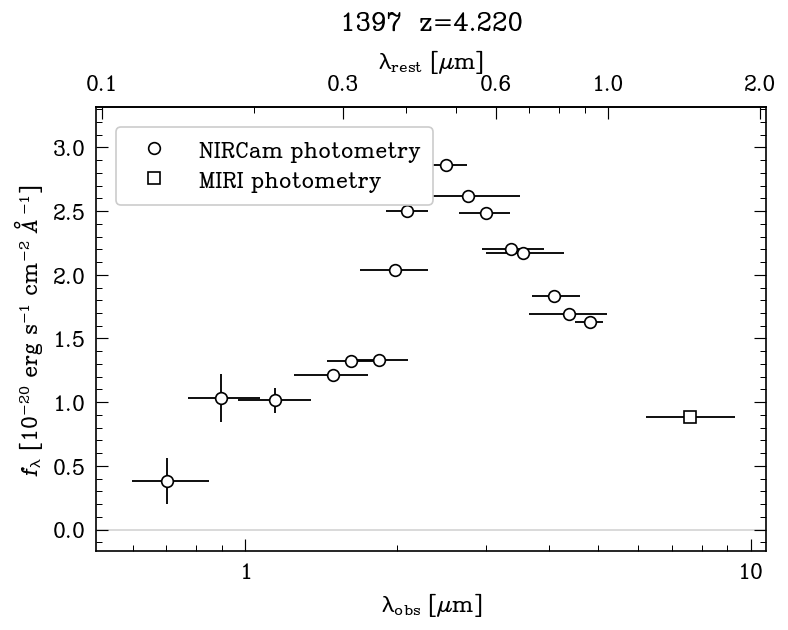

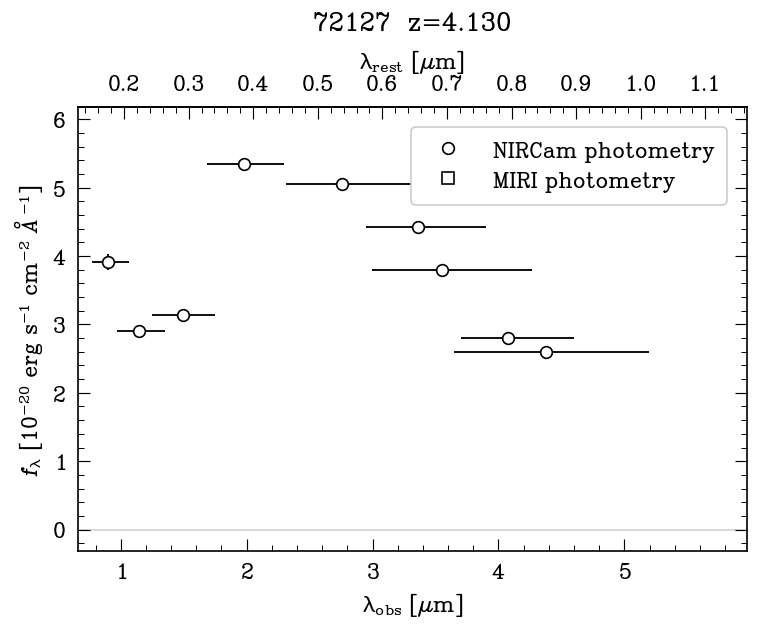

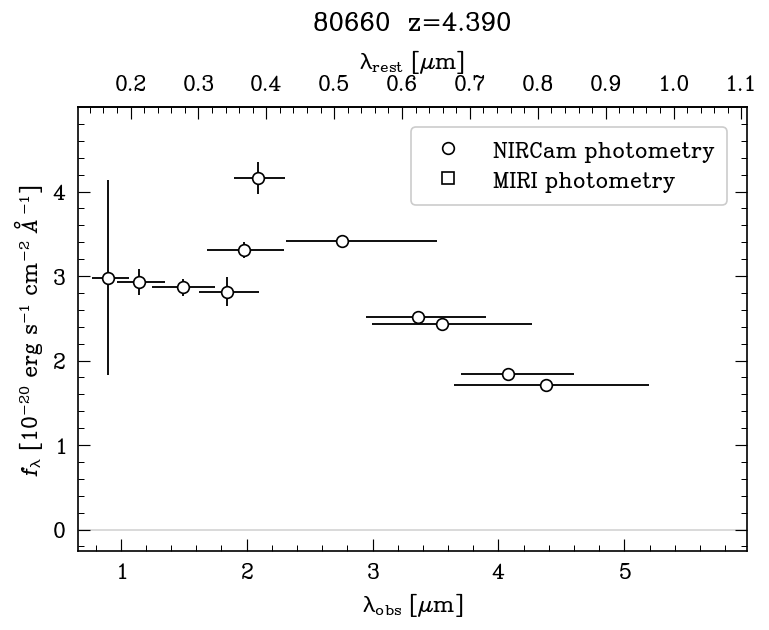

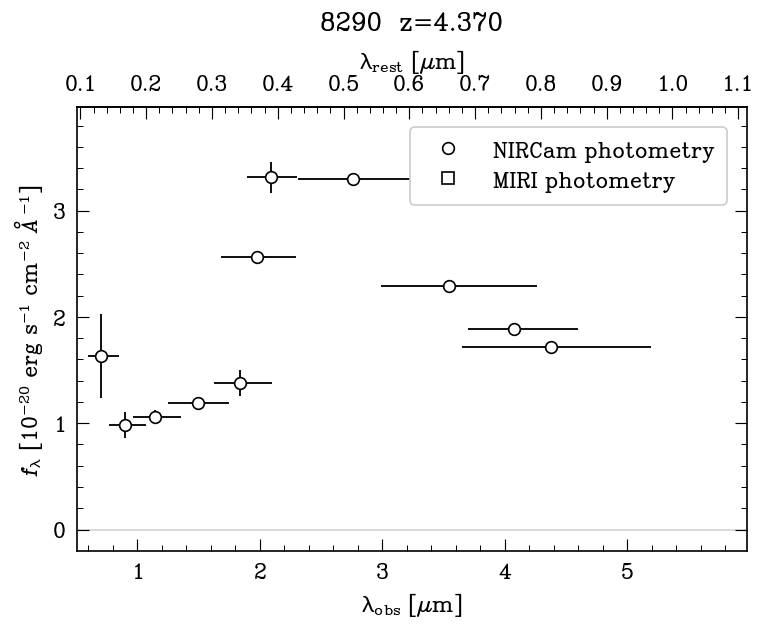

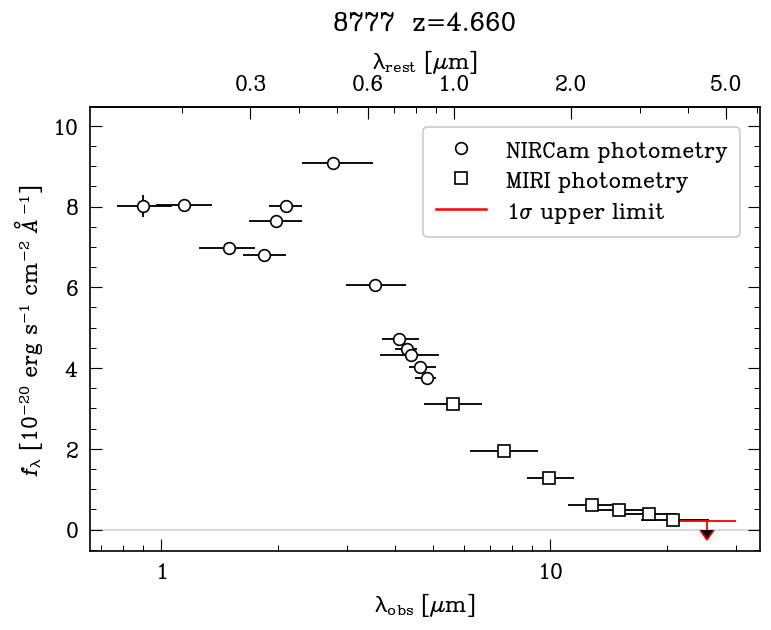

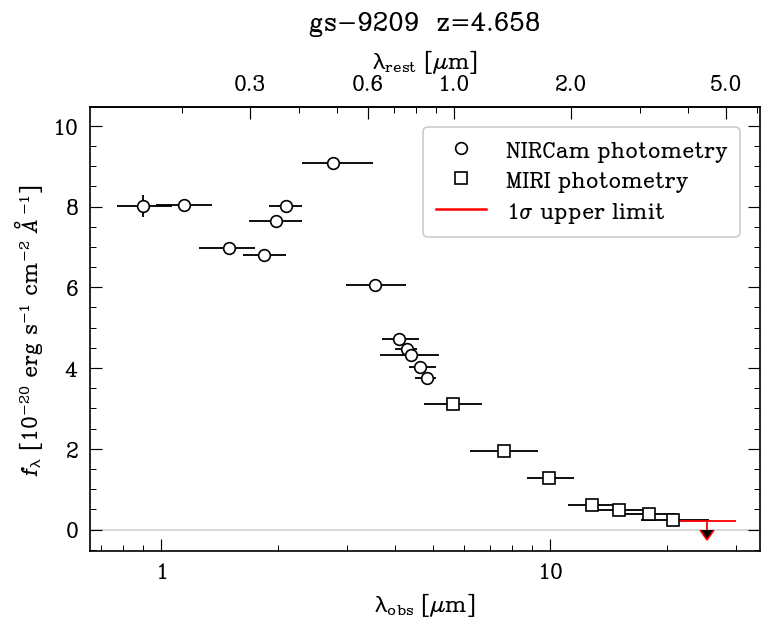

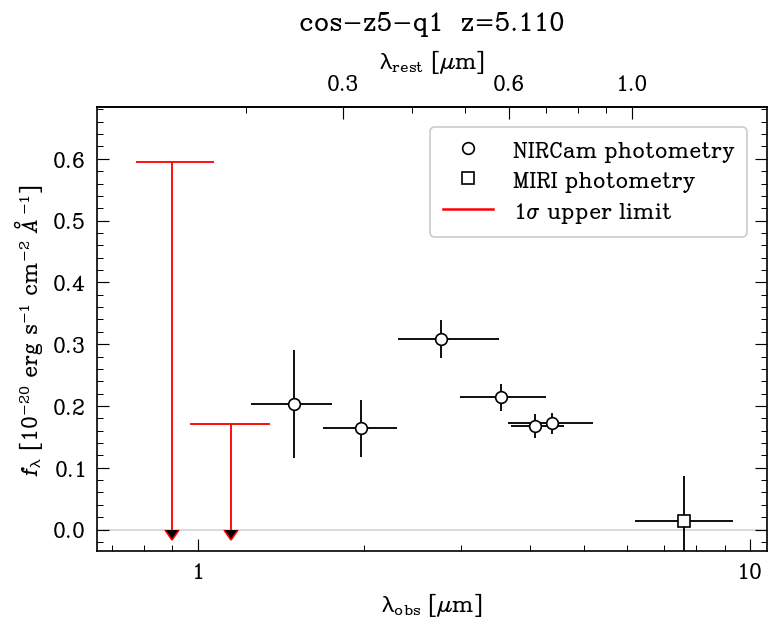

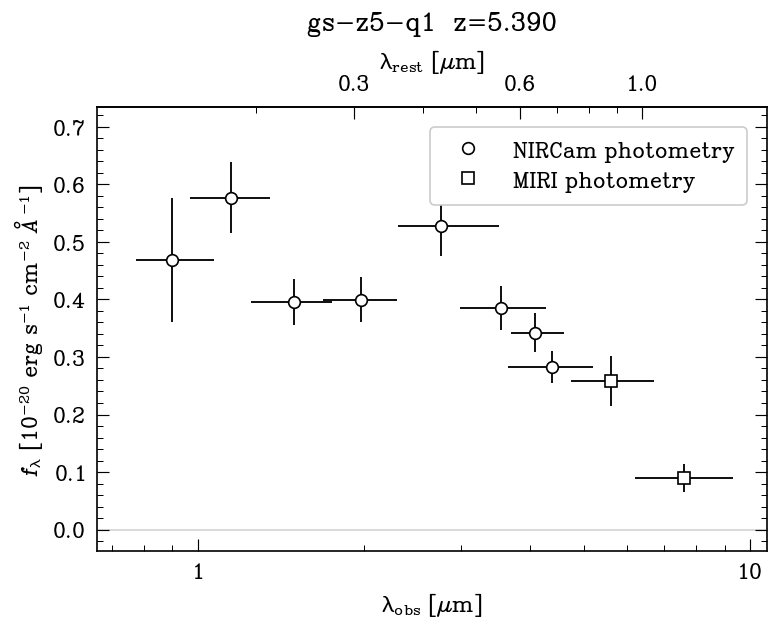

In [16]:
saved_figures = []

for target_id, file_name in photometry_files.items():
    saved_figures.append(plot_target_photometry(target_id, PHOT_DIR / file_name, galaxy_redshifts[target_id]))

saved_figures
